# 3. Revenue, Growth & Seller Performance

**Business question:** where is the revenue coming from (categories,
regions, time), and which sellers are driving it?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")
PROCESSED_DIR = Path("../data/processed")

master = pd.read_csv(PROCESSED_DIR / "master_order_items.csv", parse_dates=["order_purchase_timestamp"])
order_level = master.drop_duplicates(subset="order_id")
master.shape, order_level.shape

((112650, 37), (98666, 37))

## Revenue by product category

                               total_revenue  n_items   avg_price
product_category_name_english                                    
health_beauty                     1258681.34     9670  130.163531
watches_gifts                     1205005.68     5991  201.135984
bed_bath_table                    1036988.68    11115   93.296327
sports_leisure                     988048.97     8641  114.344285
computers_accessories              911954.32     7827  116.513903
furniture_decor                    729762.49     8334   87.564494
cool_stuff                         635290.85     3796  167.357969
housewares                         632248.66     6964   90.788148
auto                               592720.11     4235  139.957523
garden_tools                       485256.46     4347  111.630196


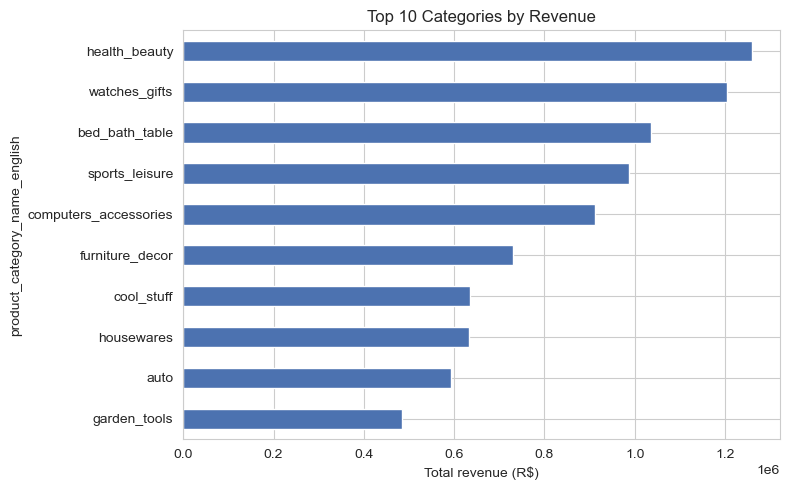

In [2]:
category_revenue = (
    master.groupby("product_category_name_english")["price"]
    .agg(total_revenue="sum", n_items="count", avg_price="mean")
    .sort_values("total_revenue", ascending=False)
    .head(10)
)
print(category_revenue)

fig, ax = plt.subplots(figsize=(8, 5))
category_revenue["total_revenue"].sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Total revenue (R$)")
ax.set_title("Top 10 Categories by Revenue")
plt.tight_layout()
plt.show()

## Monthly revenue trend

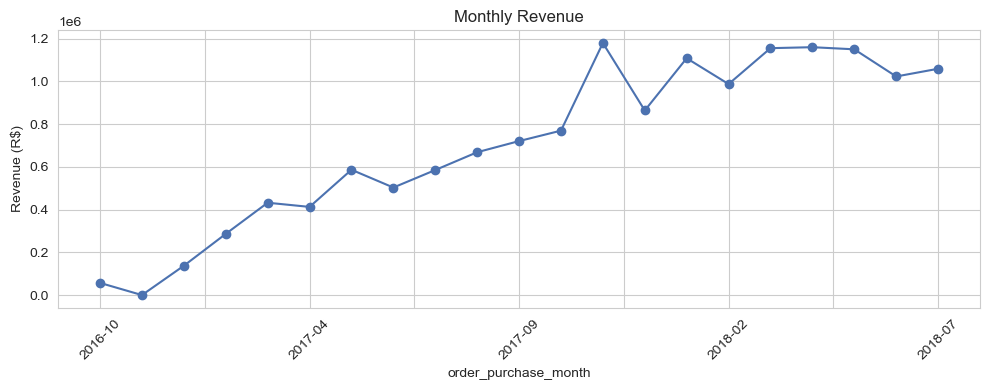

In [3]:
monthly_revenue = order_level.groupby("order_purchase_month")["payment_value_total"].sum().sort_index()

# Drop the first/last partial months (Sep 2016 and Sep/Oct 2018 have almost no data)
monthly_revenue_trimmed = monthly_revenue.iloc[1:-2]

fig, ax = plt.subplots(figsize=(10, 4))
monthly_revenue_trimmed.plot(ax=ax, marker="o", color="#4C72B0")
ax.set_ylabel("Revenue (R$)")
ax.set_title("Monthly Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Revenue by state

In [4]:
state_revenue = (
    order_level.groupby("customer_state")["payment_value_total"]
    .agg(total_revenue="sum", n_orders="count", avg_order_value="mean")
    .sort_values("total_revenue", ascending=False)
    .head(10)
)
state_revenue

,total_revenue,n_orders,avg_order_value
customer_state,,,
SP,5922248.07,41374,143.139365
RJ,2130002.87,12762,166.901964
MG,1856547.43,11544,160.823582
RS,886156.37,5432,163.136298
PR,801146.18,4998,160.293353
BA,611639.46,3358,182.143973
SC,610294.22,3612,168.962962
DF,353252.26,2125,166.236358
GO,347788.80,2007,173.287892


## Seller performance: revenue vs. review score

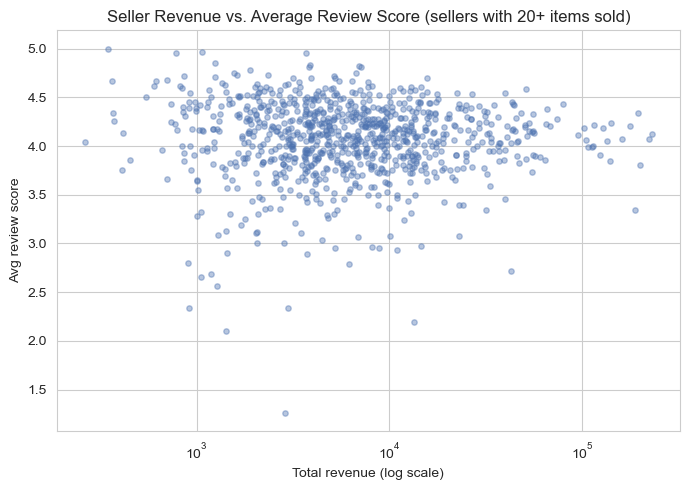

In [5]:
seller_stats = (
    master.groupby("seller_id")
    .agg(
        total_revenue=("price", "sum"),
        n_items_sold=("price", "count"),
        avg_review_score=("review_score", "mean"),
    )
    .query("n_items_sold >= 20")  # drop tiny sellers so the average is meaningful
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(seller_stats["total_revenue"], seller_stats["avg_review_score"], alpha=0.4, s=15, color="#4C72B0")
ax.set_xscale("log")
ax.set_xlabel("Total revenue (log scale)")
ax.set_ylabel("Avg review score")
ax.set_title("Seller Revenue vs. Average Review Score (sellers with 20+ items sold)")
plt.tight_layout()
plt.show()

### Deep-dive

**Category x state:** which category is the top revenue driver in
   each of the top 5 states? (hint: `groupby(["customer_state",
   "product_category_name_english"])`, then take the top row per state)


In [6]:
# Deep-dive: for each of the top states by revenue, which product
# category actually drives that revenue? This tells us whether it's
# worth running state-specific promotions/inventory by category, or
# whether the same handful of categories dominate everywhere.

TOP_N_STATES = 5

top_states = (
    order_level.groupby("customer_state")["payment_value_total"]
    .sum()
    .sort_values(ascending=False)
    .head(TOP_N_STATES)
    .index
)
print(f"Top {TOP_N_STATES} states by revenue:", list(top_states))


Top 5 states by revenue: ['SP', 'RJ', 'MG', 'RS', 'PR']


In [7]:
cat_state_revenue = (
    master[master["customer_state"].isin(top_states)]
    .groupby(["customer_state", "product_category_name_english"])["price"]
    .agg(total_revenue="sum", n_items="count")
    .reset_index()
)

# Top category per state, by revenue
top_category_per_state = (
    cat_state_revenue.sort_values("total_revenue", ascending=False)
    .groupby("customer_state")
    .first()
    .loc[top_states]  # keep in revenue-rank order
)
print("Top revenue-driving category per state:")
print(top_category_per_state[["product_category_name_english", "total_revenue", "n_items"]])

# What share of that state's revenue does the top category represent?
state_totals = cat_state_revenue.groupby("customer_state")["total_revenue"].sum()
top_category_per_state["share_of_state_revenue"] = (
    top_category_per_state["total_revenue"] / state_totals.loc[top_category_per_state.index]
)
print("\nWith share of that state's total revenue:")
print(top_category_per_state[["product_category_name_english", "share_of_state_revenue"]].round(3))

Top revenue-driving category per state:
               product_category_name_english  total_revenue  n_items
customer_state                                                      
SP                            bed_bath_table      478284.52     5235
RJ                             watches_gifts      185379.65      874
MG                             health_beauty      157558.30     1086
RS                            bed_bath_table       60270.74      614
PR                             watches_gifts       59967.04      307

With share of that state's total revenue:
               product_category_name_english  share_of_state_revenue
customer_state                                                      
SP                            bed_bath_table                   0.092
RJ                             watches_gifts                   0.102
MG                             health_beauty                   0.099
RS                            bed_bath_table                   0.080
PR                  

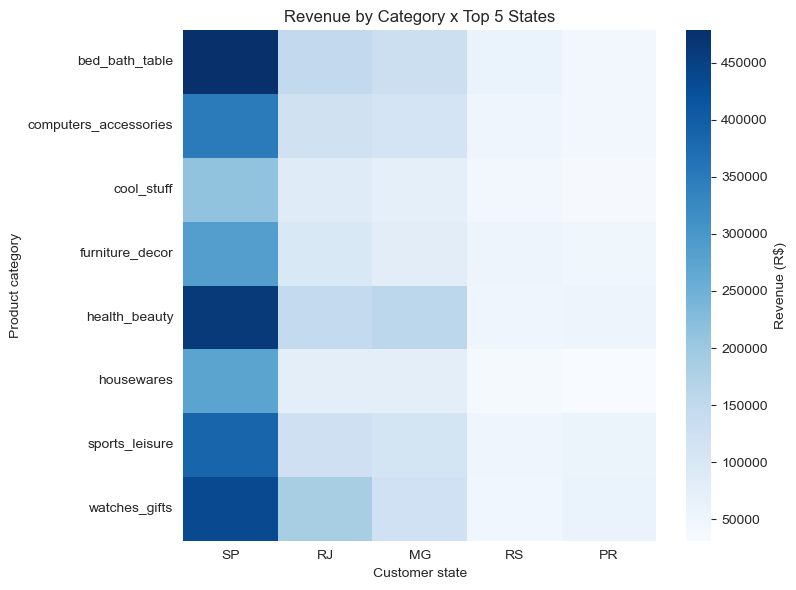

In [8]:
# Top 8 categories overall (within these states), so the heatmap stays readable
top_categories_overall = (
    cat_state_revenue.groupby("product_category_name_english")["total_revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(8)
    .index
)

pivot = (
    cat_state_revenue[cat_state_revenue["product_category_name_english"].isin(top_categories_overall)]
    .pivot(index="product_category_name_english", columns="customer_state", values="total_revenue")
    .reindex(columns=top_states)
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pivot, annot=False, cmap="Blues", ax=ax, cbar_kws={"label": "Revenue (R$)"})
ax.set_title(f"Revenue by Category x Top {TOP_N_STATES} States")
ax.set_xlabel("Customer state")
ax.set_ylabel("Product category")
plt.tight_layout()
plt.show()